# Exploring variation in cancer cell-line drug responses

## Objective
Understand the structure, coverage, and quality of the PRISM primary-screen
drug-response data before selecting a prediction task.

## Experimental unit
Each measurement describes the response of one cancer cell line to one
treatment condition. The response table stores cell lines as rows and
treatments as columns.

## Outcome
The outcome is a processed log-fold-change viability measurement relative
to controls. More negative values indicate lower relative viability signal.
These laboratory measurements do not establish clinical treatment efficacy.

## Initial questions
1. Did the response matrix load correctly?
2. Are cell-line and treatment identifiers unique?
3. How much data is missing, and where is missingness concentrated?
4. How do responses vary across cell lines and treatments?


Initial import of files and understanding of structure and descriptive statistics

In [61]:
import pandas as pd
import numpy as np
responses = pd.read_csv('../data/raw/primary-screen-replicate-collapsed-logfold-change.csv')
responses.head()

,Unnamed: 0,BRD-A00077618-236-07-6::2.5::HTS,BRD-A00100033-001-08-9::2.5::HTS,BRD-A00147595-001-01-5::2.5::HTS,BRD-A00218260-001-03-4::2.5::HTS,BRD-A00376169-001-01-6::2.5::HTS,BRD-A00520476-001-07-4::2.5::HTS,BRD-A00546892-001-02-6::2.5::HTS,BRD-A00578795-001-04-3::2.5::HTS,BRD-A00758722-001-04-9::2.5::HTS,...,BRD-K98557884-001-01-6::2.5::MTS004,BRD-K99077012-001-01-9::2.332734192::MTS004,BRD-K99199077-001-16-1::2.603211317::MTS004,BRD-K99431849-001-01-7::2.500018158::MTS004,BRD-K99447003-335-04-1::2.37737659::MTS004,BRD-K99506538-001-03-8::2.5::MTS004,BRD-K99616396-001-05-1::2.499991421::MTS004,BRD-K99879819-001-02-1::2.5187366::MTS004,BRD-K99919177-001-01-3::2.5::MTS004,BRD-M63173034-001-03-6::2.64076472::MTS004
0,ACH-000001,-0.015577,-0.449332,0.489379,0.206675,0.272730,0.021036,-0.025460,0.467158,-0.736306,...,0.429238,0.204841,0.150055,-0.575404,-0.101247,0.399233,-0.127658,-0.141651,-1.153652,0.510464
1,ACH-000007,-0.095730,0.257943,0.772349,-0.438502,-0.732832,0.779201,0.426523,-1.288508,-0.476133,...,-0.471486,0.212998,-0.123230,0.625527,0.383198,0.212031,0.349225,-0.387439,-0.831461,0.323558
2,ACH-000008,0.379480,-0.596132,0.548056,0.422269,-0.216986,0.081866,0.145335,-0.570841,-0.512119,...,-0.111951,0.534787,0.206642,-0.410153,-0.560722,-0.036088,0.158071,0.171043,-3.947090,0.099310
3,ACH-000010_FAILED_STR,0.118890,-0.231615,0.621937,-0.202707,-1.005139,-0.213739,0.020246,-0.795278,NaN,...,0.200605,-0.075356,0.610310,-0.019413,-0.202971,0.218158,-0.411009,-0.181540,-3.010225,0.090652
4,ACH-000011,0.145346,-0.499274,0.267470,0.157804,-0.272286,0.207768,0.004464,-0.191680,-0.310375,...,-0.076863,0.026002,0.139921,-0.261704,0.085339,0.447482,0.164620,-0.565251,-4.110627,0.222394


In [62]:
print(f"Shape of response df: {responses.shape}")
print(f"Unique cell lines {sum([1 for cell in responses.iloc[:,0].unique()])}")
display(responses.iloc[:5, :5])

print("\nFirst five row labels:")
print(responses.index[:5].tolist())

print("\nColumn data types:")
display(responses.dtypes.value_counts())

Shape of response df: (578, 4687)
Unique cell lines 578


,Unnamed: 0,BRD-A00077618-236-07-6::2.5::HTS,BRD-A00100033-001-08-9::2.5::HTS,BRD-A00147595-001-01-5::2.5::HTS,BRD-A00218260-001-03-4::2.5::HTS
0,ACH-000001,-0.015577,-0.449332,0.489379,0.206675
1,ACH-000007,-0.095730,0.257943,0.772349,-0.438502
2,ACH-000008,0.379480,-0.596132,0.548056,0.422269
3,ACH-000010_FAILED_STR,0.118890,-0.231615,0.621937,-0.202707
4,ACH-000011,0.145346,-0.499274,0.267470,0.157804



First five row labels:
[0, 1, 2, 3, 4]

Column data types:


float64    4686
object        1
Name: count, dtype: int64

In [63]:
#change index and first col identifuer
responses = responses.set_index("Unnamed: 0")
responses.index.name = "cell_id"

print(responses.shape)
display(responses.iloc[:5, :5])


(578, 4686)


,BRD-A00077618-236-07-6::2.5::HTS,BRD-A00100033-001-08-9::2.5::HTS,BRD-A00147595-001-01-5::2.5::HTS,BRD-A00218260-001-03-4::2.5::HTS,BRD-A00376169-001-01-6::2.5::HTS
cell_id,,,,,
ACH-000001,-0.015577,-0.449332,0.489379,0.206675,0.272730
ACH-000007,-0.095730,0.257943,0.772349,-0.438502,-0.732832
ACH-000008,0.379480,-0.596132,0.548056,0.422269,-0.216986
ACH-000010_FAILED_STR,0.118890,-0.231615,0.621937,-0.202707,-1.005139
ACH-000011,0.145346,-0.499274,0.267470,0.157804,-0.272286


In [64]:
# True means the measurement is missing.
missing = responses.isna()

print(f"Missing measurements: {missing.sum().sum():,}")
print(f"Overall missing: {missing.to_numpy().mean():.2%}")

# Missing fraction for each treatment (down each column).
missing_by_treatment = missing.mean(axis=0)

# Missing fraction for each cell line (across each row).
missing_by_cell = missing.mean(axis=1)

display(missing_by_treatment.describe())
display(missing_by_cell.describe())

Missing measurements: 76,337
Overall missing: 2.82%


count    4686.000000
mean        0.028184
std         0.020809
min         0.005190
25%         0.012111
50%         0.022491
75%         0.048443
max         0.197232
dtype: float64

count    578.000000
mean       0.028184
std        0.087758
min        0.000000
25%        0.000213
50%        0.000640
75%        0.003414
max        0.817328
dtype: float64

Overall response missingness is 2.82%, but coverage varies substantially across cell lines. I will inspect poorly covered rows before deciding whether exclusions are justified.

In [65]:
cell_coverage = pd.DataFrame({
    "n_measured": responses.notna().sum(axis=1),
    "missing_pct": missing_by_cell * 100,
}).sort_values("missing_pct", ascending=False)

display(cell_coverage.head(15))

for threshold in [5, 10, 25, 50]:
    count = (cell_coverage["missing_pct"] > threshold).sum()
    print(f"Cell lines with >{threshold}% missing: {count}")

,n_measured,missing_pct
cell_id,,
ACH-000093,856,81.732821
ACH-000958,1482,68.373880
ACH-000051,1552,66.880068
ACH-000341,1796,61.673069
ACH-000446,1905,59.346991
ACH-000399,2202,53.008963
ACH-000149,2218,52.667520
ACH-000269,2402,48.740930
ACH-001164,2837,39.457960


Cell lines with >5% missing: 99
Cell lines with >10% missing: 50
Cell lines with >25% missing: 16
Cell lines with >50% missing: 7


Low coverage alone does not establish that observed responses are unreliable. I will inspect cell metadata for patterns in missingness and retain missing responses without imputation.

In [66]:
cells = pd.read_csv("../data/raw/primary-screen-cell-line-info.csv")

coverage_details = cell_coverage.join(
    cells.set_index("row_name")[
        ["ccle_name", "primary_tissue",
         "passed_str_profiling", "str_profiling_notes"]
    ],
    how="left",
    validate="one_to_one",
)

display(coverage_details.head(20))

,n_measured,missing_pct,ccle_name,primary_tissue,passed_str_profiling,str_profiling_notes
cell_id,,,,,,
ACH-000093,856,81.732821,PANC0504_PANCREAS,pancreas,True,NaN
ACH-000958,1482,68.373880,SW48_LARGE_INTESTINE,colorectal,True,NaN
ACH-000051,1552,66.880068,TE617T_SOFT_TISSUE,rhabdomyosarcoma,True,NaN
ACH-000341,1796,61.673069,SKNFI_AUTONOMIC_GANGLIA,peripheral_nervous_system,True,NaN
ACH-000446,1905,59.346991,KPNSI9S_AUTONOMIC_GANGLIA,peripheral_nervous_system,True,NaN
ACH-000399,2202,53.008963,NCIH2196_LUNG,lung,True,NaN
ACH-000149,2218,52.667520,SKNSH_AUTONOMIC_GANGLIA,peripheral_nervous_system,True,NaN
ACH-000269,2402,48.740930,AM38_CENTRAL_NERVOUS_SYSTEM,central_nervous_system,True,NaN
ACH-001164,2837,39.457960,CCLFPEDS0003T_SOFT_TISSUE,soft_tissue,True,NaN


In [67]:
#Next, inspect identity failures across all rows, rather than just the lowest-coverage rows:

display(
    coverage_details["passed_str_profiling"].value_counts(dropna=False)
)

failed_identity = coverage_details[
    coverage_details["passed_str_profiling"].eq(False)
]

display(
    failed_identity[
        ["missing_pct", "str_profiling_notes"]
    ]
)

passed_str_profiling
True     568
False     10
Name: count, dtype: int64

,missing_pct,str_profiling_notes
cell_id,,
ACH-000539_FAILED_STR,39.244558,STR profile matches cell line SW569
ACH-000010_FAILED_STR,13.486983,STR matches to NCI-H1581 (known misidentified ...
ACH-000511_FAILED_STR,11.929151,STR matches R1192/Caki1
ACH-001078_FAILED_STR,11.630388,STR matches cell line LS513
ACH-000028_FAILED_STR,6.807512,STR matches MCF7 (known misidentified)
ACH-000807_FAILED_STR,0.512164,STR shows cross contamination with TOM1 and po...
ACH-000409_FAILED_STR,0.277422,"STR does not match profile, missidentified (ST..."
ACH-000925_FAILED_STR,0.000000,STR matches LS180
ACH-000992_FAILED_STR,0.000000,STR shows mouse contamination


In [68]:
# Align metadata to the response matrix's original row order.
identity_status = coverage_details["passed_str_profiling"].reindex(
    responses.index
)

assert identity_status.notna().all(), "Some rows lack identity-check information."

responses_verified = responses.loc[identity_status.eq(True)].copy()

print("Original shape:", responses.shape)
print("Passed identity check:", responses_verified.shape)

Original shape: (578, 4686)
Passed identity check: (568, 4686)


Excluded rows that failed cell-identity checks from subsequent biological analysis; retained low-coverage rows pending a treatment-specific assessment.

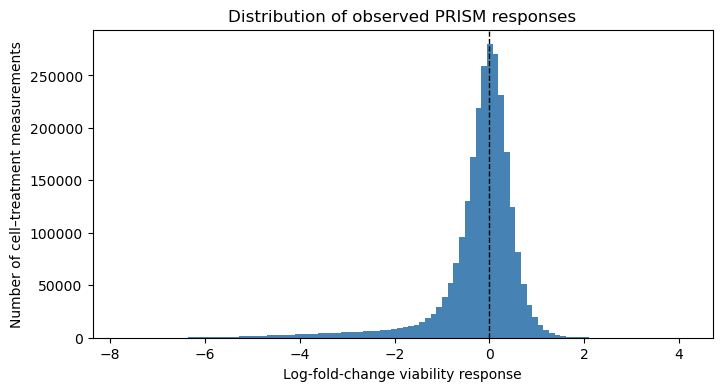

In [69]:
import matplotlib.pyplot as plt

# Flatten the matrix into observed measurements for this overview.
values = responses_verified.to_numpy().ravel()
values = values[pd.notna(values)]

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(values, bins=100, color="steelblue", edgecolor="none")
ax.axvline(0, color="black", linestyle="--", linewidth=1)

ax.set(
    title="Distribution of observed PRISM responses",
    xlabel="Log-fold-change viability response",
    ylabel="Number of cell–treatment measurements",
)

plt.show()


Responses cluster near zero with a pronounced negative tail. Because this distribution combines all treatments, I next examine treatment-level response patterns.

In [70]:
treatment_summary = pd.DataFrame({
    "n_measured": responses_verified.count(),
    "median_response": responses_verified.median(),
    "q10": responses_verified.quantile(0.10),
    "q90": responses_verified.quantile(0.90),
})

treatment_summary["response_spread"] = (
    treatment_summary["q90"] - treatment_summary["q10"]
)

display(
    treatment_summary.sort_values("median_response").head(10)
)

display(
    treatment_summary.sort_values("response_spread", ascending=False).head(10)
)


,n_measured,median_response,q10,q90,response_spread
BRD-K61397605-001-03-4::2.5::HTS,560,-4.432454,-6.069124,-2.745455,3.323669
BRD-K78659596-001-03-9::2.5::HTS,554,-4.306550,-5.800106,-2.731502,3.068604
BRD-A66419424-001-02-4::2.5::HTS,554,-4.207796,-5.754825,-2.538331,3.216494
BRD-K99475619-001-01-2::2.5::HTS,548,-4.200724,-5.859215,-2.477872,3.381342
BRD-K40331046-305-01-5::2.5::HTS,561,-4.176318,-5.808697,-2.213745,3.594952
BRD-K88510285-001-11-1::2.5::HTS,561,-4.171768,-5.738399,-2.613078,3.125321
BRD-K51911221-001-01-2::2.5::HTS,564,-4.156542,-5.774491,-2.429459,3.345032
BRD-K69650333-003-14-0::2.5::HTS,556,-4.154443,-5.632363,-2.400179,3.232184
BRD-K76674262-001-03-3::2.5::HTS,564,-4.150275,-5.828568,-2.431291,3.397277
BRD-K92093830-003-30-8::2.5::HTS,561,-4.117382,-5.746311,-2.067960,3.678350


,n_measured,median_response,q10,q90,response_spread
BRD-K66296774-236-11-3::2.63::HTS,541,-2.049995,-3.984564,0.455427,4.439991
BRD-K22134346-001-24-9::2.42::HTS,530,-0.974480,-3.250591,1.124531,4.375122
BRD-K96631475-001-02-4::2.43::HTS,530,-0.877953,-3.095011,1.272449,4.367460
BRD-K75958547-238-01-0::2.5::HTS,562,-0.755417,-3.154569,1.209727,4.364296
BRD-K41213548-001-02-0::2.5::HTS,548,-2.228847,-4.136194,0.184614,4.320808
BRD-K00317371-001-06-1::2.4::HTS,530,-1.268616,-3.714939,0.489713,4.204652
BRD-K96259238-001-01-4::2.5::HTS,561,-1.889229,-4.196484,-0.016250,4.180234
BRD-K13167095-001-02-9::2.5::HTS,564,-3.461594,-5.171494,-1.025540,4.145954
BRD-K58770988-001-01-8::2.5::HTS,561,-2.242594,-4.240674,-0.163120,4.077554
BRD-K02407574-001-09-7::2.5::HTS,564,-2.009209,-4.008516,-0.024568,3.983948


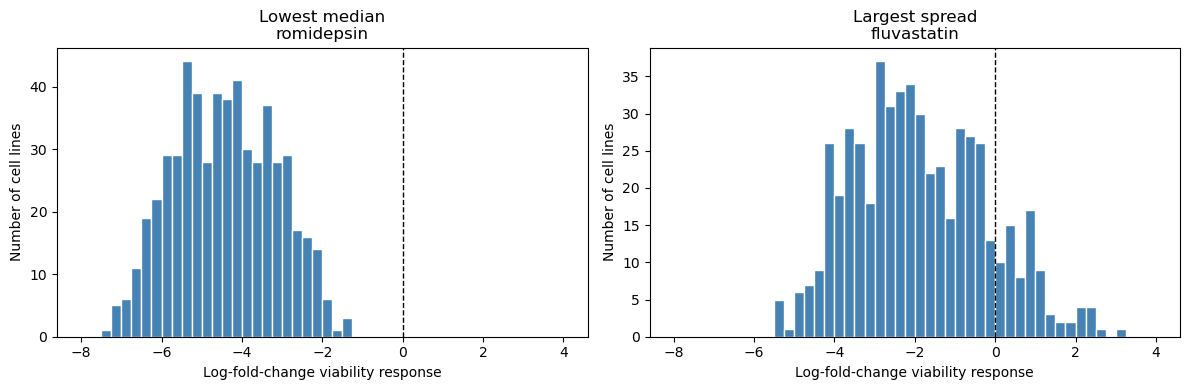

In [71]:
treatments = pd.read_csv(
    "../data/raw/primary-screen-replicate-collapsed-treatment-info.csv"
)

treatment_details = treatment_summary.join(
    treatments.set_index("column_name")[["name", "dose", "moa"]],
    how="left",
    validate="one_to_one",
)

selected = {
    "Lowest median": treatment_details["median_response"].idxmin(),
    "Largest spread": treatment_details["response_spread"].idxmax(),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

# Identical bin boundaries make the shapes easier to compare.
bins = [
    -8 + i * 0.25
    for i in range(49)
]

for ax, (label, treatment_id) in zip(axes, selected.items()):
    data = responses_verified[treatment_id].dropna()
    name = treatment_details.loc[treatment_id, "name"]

    ax.hist(data, bins=bins, color="steelblue", edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=f"{label}\n{name}",
        xlabel="Log-fold-change viability response",
        ylabel="Number of cell lines",
    )

plt.tight_layout()
plt.show()

Romidepsin responses were consistently negative across measured cell lines,
whereas fluvastatin showed a broader range spanning negative and positive
values. These selected examples motivate investigating cell-line differences,
but do not establish the source of response variation.

In [72]:
cell_summary = pd.DataFrame({
    "n_measured": responses_verified.count(axis=1),
    "median_response": responses_verified.median(axis=1),
    "q10": responses_verified.quantile(0.10, axis=1),
    "q90": responses_verified.quantile(0.90, axis=1),
})

cell_summary["response_spread"] = (
    cell_summary["q90"] - cell_summary["q10"]
)

display(cell_summary.sort_values("median_response").head(10))
display(cell_summary.sort_values("response_spread", ascending=False).head(10))


,n_measured,median_response,q10,q90,response_spread
cell_id,,,,,
ACH-000051,1552,-0.398956,-1.643456,0.849030,2.492485
ACH-000446,1905,-0.355233,-1.666758,0.695716,2.362473
ACH-000269,2402,-0.323540,-1.638354,0.910840,2.549194
ACH-000756,4685,-0.212442,-1.278099,0.430800,1.708899
ACH-000222,4686,-0.206507,-1.135892,0.210143,1.346034
ACH-000123,4676,-0.202396,-1.252676,0.458235,1.710910
ACH-000418,4673,-0.200395,-1.300790,0.801154,2.101945
ACH-000940,4685,-0.196791,-1.600694,0.270540,1.871233
ACH-000430,4683,-0.194388,-1.539510,0.592663,2.132173


,n_measured,median_response,q10,q90,response_spread
cell_id,,,,,
ACH-000269,2402,-0.323540,-1.638354,0.910840,2.549194
ACH-000051,1552,-0.398956,-1.643456,0.849030,2.492485
ACH-000446,1905,-0.355233,-1.666758,0.695716,2.362473
ACH-000847,4684,0.255090,-1.273805,1.074986,2.348791
ACH-001099,4334,-0.185026,-1.460581,0.840025,2.300606
ACH-000139,4341,-0.063497,-1.382937,0.816641,2.199578
ACH-000163,4140,0.022511,-1.321749,0.859800,2.181549
ACH-000958,1482,-0.092600,-1.078218,1.066211,2.144430
ACH-000686,3708,-0.021073,-1.246715,0.890597,2.137312


Selected treatments showed substantial variation across cell lines. However,
these extreme examples do not establish whether treatment or cell-line
identity is more predictive. Several extreme cell-line summaries also have
low coverage, which may affect comparisons.

In [73]:
spread_comparison = pd.DataFrame({
    "Across cell lines, within each treatment":
        treatment_summary["response_spread"].describe(),
    "Across treatments, within each cell line":
        cell_summary["response_spread"].describe(),
})

display(spread_comparison)


,"Across cell lines, within each treatment","Across treatments, within each cell line"
count,4686.000000,568.000000
mean,1.211326,1.487493
std,0.680802,0.257061
min,0.615624,0.955955
25%,0.860247,1.312528
50%,0.950432,1.442014
75%,1.166014,1.626531
max,4.439991,2.549194


The median response spread (q90 − q10) was 0.95 across cell lines within
treatments and 1.44 across treatments within cell lines. Treatment spreads
were more heterogeneous, with a small subset showing much larger variation.
These summaries motivate treatment-specific baselines and investigating
whether cell-line features explain additional response differences.


Fluvastatin is the treatment with the highest variance in the response variable, so this is a good place to start idnetifying where variance comes from accross different cell lines. To start exploring lets join the cell line meta data which will give us more signal on how treataments interact with cell line traits. We will start by breaking this down by tissue type to seee if high variability treatments can be explained by cell tissue type.


In [74]:
#find fluvastin
fluvastatin_matches = treatment_details.loc[
    treatment_details["name"].str.contains(
        "fluvastatin", case=False, na=False
    )
]

display(
    fluvastatin_matches[
        ["name", "dose", "n_measured", "median_response", "response_spread"]
    ]
)


,name,dose,n_measured,median_response,response_spread
BRD-K66296774-236-11-3::2.63::HTS,fluvastatin,2.63,541,-2.049995,4.439991


In [75]:
fluvastatin_id = fluvastatin_matches.index[0]

#Extract responses for this specific treatment condition.
fluvastatin_responses = (
    responses_verified[fluvastatin_id]
    .rename("response")
    .to_frame()
)

fluvastatin_responses.head()




,response
cell_id,
ACH-000001,0.282004
ACH-000007,0.872123
ACH-000008,-4.188289
ACH-000011,-1.168344
ACH-000012,NaN


In [76]:
#Use the original screen row identifier to align cell metadata.
cell_metadata = cells.set_index("row_name")[
    ["ccle_name", "primary_tissue"]
]

#join cell metadata to fluvastatin response df
fluvastatin_cells = fluvastatin_responses.join(
    cell_metadata,
    how="left",
    validate="one_to_one",
)

display(fluvastatin_cells.head())

print("Cell lines:", len(fluvastatin_cells))
print("Missing responses:", fluvastatin_cells["response"].isna().sum())
print("Missing tissue labels:", fluvastatin_cells["primary_tissue"].isna().sum())


,response,ccle_name,primary_tissue
cell_id,,,
ACH-000001,0.282004,NIHOVCAR3_OVARY,ovary
ACH-000007,0.872123,LS513_LARGE_INTESTINE,colorectal
ACH-000008,-4.188289,A101D_SKIN,skin
ACH-000011,-1.168344,253J_URINARY_TRACT,urinary_tract
ACH-000012,NaN,HCC827_LUNG,lung


Cell lines: 568
Missing responses: 27
Missing tissue labels: 0


In [77]:
tissue_summary = (
    fluvastatin_cells
    .groupby("primary_tissue", dropna=False)
    .agg(
        n_cells=("response", "size"),
        n_observed=("response", "count"),
        median_response=("response", "median"),
        q10=("response", lambda x: x.quantile(0.10)),
        q90=("response", lambda x: x.quantile(0.90)),
    )
)

tissue_summary["response_spread"] = (
    tissue_summary["q90"] - tissue_summary["q10"]
)

tissue_summary = tissue_summary.sort_values("median_response")

display(tissue_summary)

,n_cells,n_observed,median_response,q10,q90,response_spread
primary_tissue,,,,,,
central_nervous_system,42,40,-2.881714,-4.081702,-1.012200,3.069502
kidney,19,19,-2.745266,-3.706153,-0.853782,2.852371
fibroblast,1,1,-2.655151,-2.655151,-2.655151,0.000000
bone,23,23,-2.642329,-4.019398,-0.984687,3.034711
soft_tissue,5,5,-2.594351,-4.477465,-1.394870,3.082596
mesothelioma,9,8,-2.430630,-3.487188,-1.172508,2.314680
ovary,38,36,-2.412739,-3.980943,-0.294249,3.686694
skin,43,39,-2.410752,-4.205389,-0.123395,4.081995
upper_aerodigestive,27,26,-2.381777,-4.088295,-0.866820,3.221475


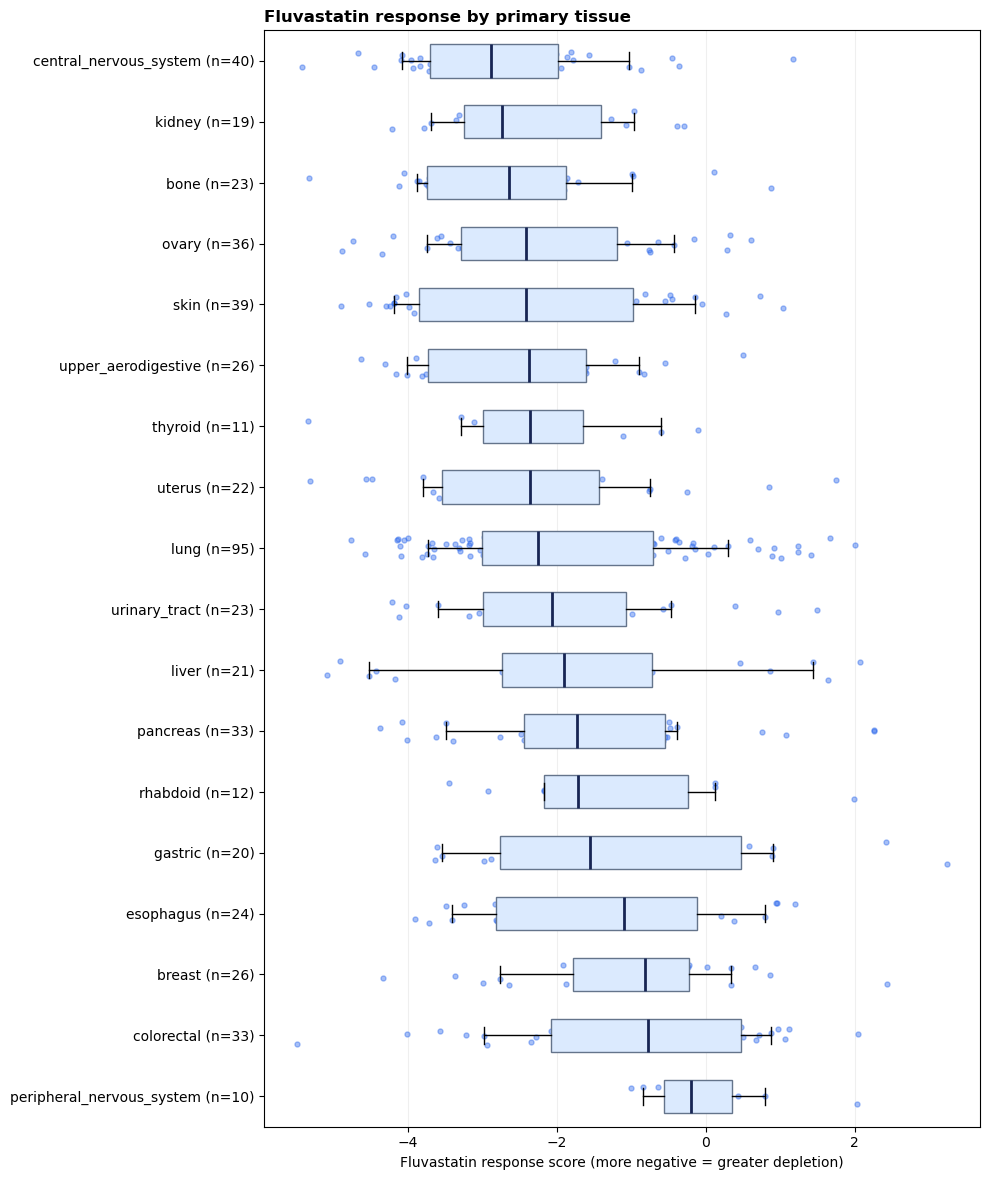

In [78]:
# Use the number of measured responses to decide which tissues to display.
min_observed = 10
tissues = (
    tissue_summary.loc[tissue_summary["n_observed"] >= min_observed]
    .sort_values("median_response")
)

responses_by_tissue = [
    fluvastatin_cells.loc[
        fluvastatin_cells["primary_tissue"].eq(tissue), "response"
    ].dropna()
    for tissue in tissues.index
]

fig, ax = plt.subplots(figsize=(10, 2 + 0.55 * len(tissues)))

ax.boxplot(
    responses_by_tissue,
    vert=False,
    widths=0.55,
    whis=(10, 90),
    showfliers=False,  # All observations are drawn as dots below.
    patch_artist=True,
    boxprops={"facecolor": "#dbeafe", "edgecolor": "#64748b"},
    medianprops={"color": "#172554", "linewidth": 2},
)

# Jitter only the vertical position so overlapping observations are visible.
rng = np.random.default_rng(42)
for position, responses in enumerate(responses_by_tissue, start=1):
    jitter = rng.uniform(-0.18, 0.18, size=len(responses))
    ax.scatter(responses, position + jitter, s=13, color="#2563eb", alpha=0.4)

positions = range(1, len(tissues) + 1)
labels = [
    f"{tissue} (n={count})"
    for tissue, count in tissues["n_observed"].items()
]
ax.set_yticks(positions, labels=labels)
ax.invert_yaxis()
ax.set_xlabel("Fluvastatin response score (more negative = greater depletion)")
ax.set_title("Fluvastatin response by primary tissue", loc="left", weight="bold")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

At this dose, central nervous system cell lines showed greater median depletion under fluvastatin than lung cell lines (−2.88 versus −2.26), although the middle 50% of their responses overlapped. Spread also varied by tissue. For example, the middle 50% of responses covered a wider range in gastric lines than in breast lines. These patterns suggest that tissue may help predict a typical response, while individual lines from the same tissue can respond quite differently.


In [79]:
from sklearn.model_selection import KFold
# Use every measured cell line, including tissues omitted from the plot.
evaluation = fluvastatin_cells.dropna(subset=["response"]).copy()
evaluation["overall_prediction"] = float("nan")
evaluation["tissue_prediction"] = float("nan")
evaluation["used_fallback"] = False

folds = KFold(n_splits=5, shuffle=True, random_state=42)

for train_idx, test_idx in folds.split(evaluation):
    train = evaluation.iloc[train_idx]
    test = evaluation.iloc[test_idx]

    overall_median = train["response"].median()
    tissue_medians = train.groupby("primary_tissue")["response"].median()
    tissue_predictions = test["primary_tissue"].map(tissue_medians)

    # If a held-out tissue has no training examples, use the overall median.
    evaluation.loc[test.index, "overall_prediction"] = overall_median
    evaluation.loc[test.index, "tissue_prediction"] = tissue_predictions.fillna(overall_median)
    evaluation.loc[test.index, "used_fallback"] = tissue_predictions.isna()

# Mean absolute error (MAE) is the average distance from the measured response.
overall_mae = (evaluation["response"] - evaluation["overall_prediction"]).abs().mean()
tissue_mae = (evaluation["response"] - evaluation["tissue_prediction"]).abs().mean()

display(pd.Series({
    "Overall median MAE": overall_mae,
    "Tissue median MAE": tissue_mae,
    "MAE improvement from using tissue": overall_mae - tissue_mae,
}).round(3))

print(f"Evaluated {len(evaluation)} cell lines.")
print(f"Used the overall median as a fallback for {evaluation['used_fallback'].sum()} lines.")


Overall median MAE                   1.372
Tissue median MAE                    1.338
MAE improvement from using tissue    0.034
dtype: float64

Evaluated 541 cell lines.
Used the overall median as a fallback for 1 lines.



### Does primary tissue improve response predictions across treatments?

For fluvastatin, using a tissue-specific median reduced held-out mean absolute
error (MAE) from 1.372 to 1.338, an improvement of 0.034 response-score units.
I selected fluvastatin because its responses varied widely across cell lines.
I now want to see how often tissue improves predictions across the full screen.

I assign each verified cell line to one of five folds and keep that assignment
fixed across treatments. For each held-out fold and treatment condition, I
compare two predictions: the median response across all training lines and the
median among training lines from the same tissue. If that tissue has no
measured training response for the treatment, I use the overall training median.

I score both methods on the same observed responses. A positive MAE improvement
means that using tissue reduced prediction error for that treatment.


,n_scored,n_fallback,overall_mae,tissue_mae,mae_improvement,name,dose
BRD-K66296774-236-11-3::2.63::HTS,541,1,1.364,1.329,0.035,fluvastatin,2.63


Treatments scored: 4,686
Treatments with lower MAE using tissue: 7.2%


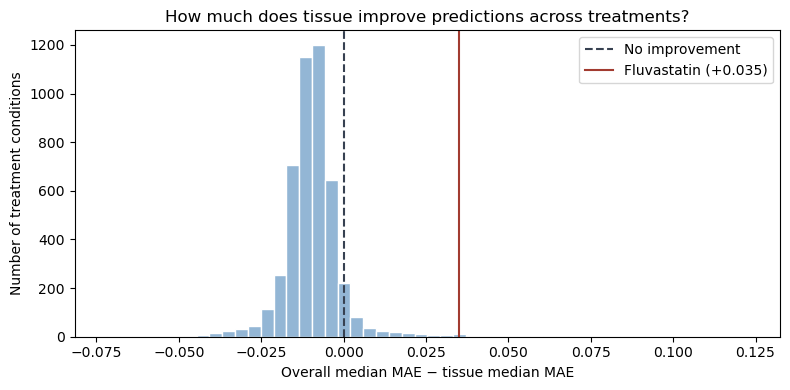

In [80]:
# Rows are verified cell lines. Columns are treatment conditions.
responses = responses_verified
tissue = cell_metadata["primary_tissue"].reindex(responses.index)

# Split the rows once. Every treatment column uses these same five folds.
folds = KFold(n_splits=5, shuffle=True, random_state=42)

# Accumulate errors by treatment so each measured test response gets equal weight.
overall_error = pd.Series(0.0, index=responses.columns)
tissue_error = pd.Series(0.0, index=responses.columns)
n_scored = pd.Series(0, index=responses.columns)
n_fallback = pd.Series(0, index=responses.columns)

for train_idx, test_idx in folds.split(responses):
    train = responses.iloc[train_idx]
    test = responses.iloc[test_idx]

    # One overall median per treatment, learned from training lines only.
    overall_medians = train.median()

    # One median per tissue and treatment, also learned from training lines only.
    tissue_medians = train.groupby(tissue.iloc[train_idx]).median()

    # Look up the tissue row for each test line, preserving test-line order.
    predictions = tissue_medians.reindex(tissue.iloc[test_idx].to_numpy())
    predictions.index = test.index

    # A tissue can lack training measurements for one drug but have them for another.
    fallback = predictions.isna() & test.notna() & overall_medians.notna()
    predictions = predictions.fillna(overall_medians)

    overall_errors = test.sub(overall_medians, axis="columns").abs()
    tissue_errors = (test - predictions).abs()

    overall_error += overall_errors.sum()
    tissue_error += tissue_errors.sum()
    n_scored += overall_errors.count()
    n_fallback += fallback.sum()

# Divide total absolute error by the number of scored lines for each treatment.
denominator = n_scored.where(n_scored > 0)
treatment_cv = pd.DataFrame({
    "n_scored": n_scored,
    "n_fallback": n_fallback,
    "overall_mae": overall_error / denominator,
    "tissue_mae": tissue_error / denominator,
})
treatment_cv["mae_improvement"] = (
    treatment_cv["overall_mae"] - treatment_cv["tissue_mae"]
)
treatment_cv = treatment_cv.join(treatment_details[["name", "dose"]])

# Locate fluvastatin in the screen-wide distribution.
improvements = treatment_cv["mae_improvement"].dropna()
fluvastatin_gain = treatment_cv.loc[fluvastatin_id, "mae_improvement"]

display(treatment_cv.loc[[fluvastatin_id]].round(3))
print(f"Treatments scored: {len(improvements):,}")
print(f"Treatments with lower MAE using tissue: {improvements.gt(0).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(improvements, bins=50, color="#93b6d5", edgecolor="white")
ax.axvline(0, color="#374151", linestyle="--", label="No improvement")
ax.axvline(fluvastatin_gain, color="#a23b30", label=f"Fluvastatin ({fluvastatin_gain:+.3f})")
ax.set(
    title="How much does tissue improve predictions across treatments?",
    xlabel="Overall median MAE − tissue median MAE",
    ylabel="Number of treatment conditions",
)
ax.legend()
fig.tight_layout()
plt.show()


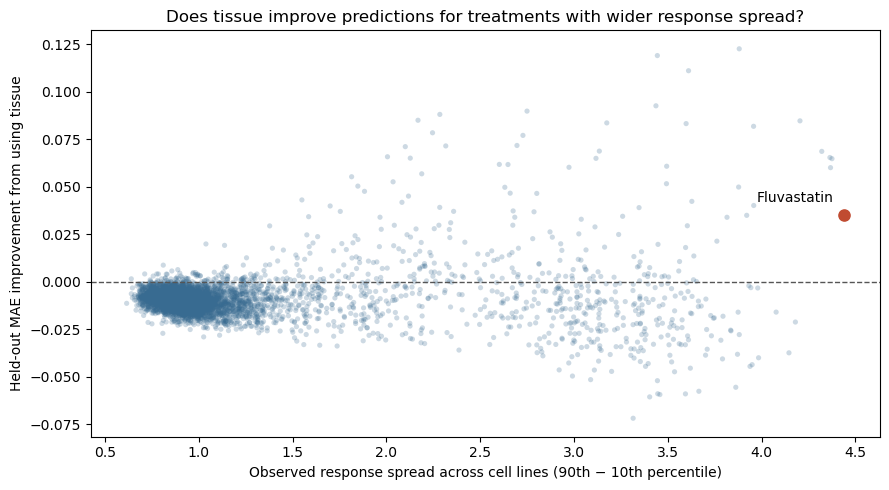

Fluvastatin MAE improvement: +0.035


In [81]:
# Match each treatment's observed response spread to its held-out MAE improvement.
spread_vs_gain = (
    treatment_cv[["name", "mae_improvement"]]
    .join(treatment_details["response_spread"], validate="one_to_one")
    .dropna(subset=["response_spread", "mae_improvement"])
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    spread_vs_gain["response_spread"],
    spread_vs_gain["mae_improvement"],
    s=14,
    alpha=0.25,
    color="#386b91",
    edgecolors="none",
)
ax.axhline(0, color="#555555", linestyle="--", linewidth=1)

fluvastatin = spread_vs_gain.loc[fluvastatin_id]
x = fluvastatin["response_spread"]
y = fluvastatin["mae_improvement"]
ax.scatter(x, y, s=65, color="#c04b31", zorder=3)
ax.annotate(
    "Fluvastatin",
    xy=(x, y),
    xytext=(-8, 10),
    textcoords="offset points",
    ha="right",
)

ax.set(
    title="Does tissue improve predictions for treatments with wider response spread?",
    xlabel="Observed response spread across cell lines (90th − 10th percentile)",
    ylabel="Held-out MAE improvement from using tissue",
)
fig.tight_layout()
plt.show()

# Compare fluvastatin with other high-spread treatments.
high_spread = spread_vs_gain["response_spread"] >= spread_vs_gain["response_spread"].quantile(0.90)
peers = spread_vs_gain.loc[high_spread].drop(index=fluvastatin_id, errors="ignore")

print(f"Fluvastatin MAE improvement: {y:+.3f}")

### Does tissue help more when treatment responses vary widely?

As response spread increased, the change in held-out MAE became more variable.
Some high-spread treatments benefited from tissue-specific predictions,
including fluvastatin, while others had larger errors. The plot shows no clear
trend toward better predictions as response spread increases.

Across the full screen, tissue-specific medians reduced MAE for only 7.2% of
treatment conditions. I’ll keep the overall treatment median as the baseline
for predicting response in a new cell line.

### Prepare cell-line features for response prediction

Tissue-specific medians improved on the treatment-only baseline for 7.2% of
treatment conditions. I’ll use that baseline to evaluate whether more detailed
cell-line features help predict responses across the screen.

First, I’ll check that each verified PRISM cell line has a unique DepMap ID.
Then I’ll use that ID to join cell-line annotations and measure how much
information each field adds. I’ll keep all verified lines and report missing
annotations before choosing features for modeling. When I add baseline gene
expression, I’ll check its coverage separately.


In [82]:
# Start with the exact cell lines used in the response analysis.
verified_metadata = (
    cells.set_index("row_name", verify_integrity=True)
    .loc[responses_verified.index, ["ccle_name", "primary_tissue", "depmap_id"]]
    .copy()
)

# Preserve missing IDs and treat blank or whitespace-only IDs as missing.
depmap_ids = verified_metadata["depmap_id"].astype("string").str.strip()
verified_metadata["depmap_id"] = depmap_ids.replace("", pd.NA)

missing_id = verified_metadata["depmap_id"].isna()
shared_id = verified_metadata["depmap_id"].duplicated(keep=False) & ~missing_id

display(pd.Series({
    "Verified PRISM rows": len(verified_metadata),
    "Rows missing a DepMap ID": missing_id.sum(),
    "Distinct nonmissing DepMap IDs": verified_metadata["depmap_id"].nunique(),
    "Rows sharing a nonmissing DepMap ID": shared_id.sum(),
}, name="count").to_frame())

if (missing_id | shared_id).any():
    display(verified_metadata.loc[missing_id | shared_id].sort_values("depmap_id"))

,count
Verified PRISM rows,568
Rows missing a DepMap ID,0
Distinct nonmissing DepMap IDs,568
Rows sharing a nonmissing DepMap ID,0


In [83]:
annotation_fields = ["primary_disease", "lineage_subtype", "primary_or_metastasis"]

sample_info = (
    pd.read_csv("../data/raw/sample_info.csv", usecols=["DepMap_ID", *annotation_fields])
    .set_index("DepMap_ID", verify_integrity=True)
)

cell_features = verified_metadata.join(
    sample_info,
    on="depmap_id",
    how="left",
    validate="one_to_one",
)

# A cell line can match the catalog and still be missing a particular annotation.
matched = cell_features["depmap_id"].isin(sample_info.index)
print(f"Matched to the DepMap catalog: {matched.sum()} of {len(cell_features)} cell lines")

annotations = cell_features[annotation_fields]
display(pd.DataFrame({
    "observed": annotations.count(),
    "missing": annotations.isna().sum(),
    "distinct_values": annotations.nunique(),
}))


Matched to the DepMap catalog: 568 of 568 cell lines


,observed,missing,distinct_values
primary_disease,568,0,24
lineage_subtype,567,1,48
primary_or_metastasis,497,71,2


In [84]:
# Count verified cell lines in each tissue–subtype group across the full screen.
subtype_counts = (
    cell_features.groupby(["primary_tissue", "lineage_subtype"], dropna=False)
    .size()
    .rename("n_cell_lines")
    .reset_index()
)

# Inspect lung as one concrete example.
display(
    subtype_counts.loc[subtype_counts["primary_tissue"].eq("lung")]
    .sort_values("n_cell_lines", ascending=False)
    .reset_index(drop=True)
)

# Check how common very small labeled groups are across all tissues.
labeled_groups = subtype_counts.dropna(subset=["lineage_subtype"])
print(f"Tissue–subtype groups: {len(labeled_groups)}")
print(f"Groups with only one cell line: {labeled_groups['n_cell_lines'].eq(1).sum()}")


,primary_tissue,lineage_subtype,n_cell_lines
0,lung,NSCLC,89
1,lung,SCLC,11
2,lung,lung_carcinoid,1


Tissue–subtype groups: 48
Groups with only one cell line: 19


Subtype annotations add detail within tissue groups. For example, the 101
verified lung lines include 89 NSCLC, 11 SCLC, and one lung carcinoid line.
Across the screen, 19 of 48 labeled tissue–subtype groups contain only one
line. A predictor based on subtype medians would therefore need a fallback
for unseen groups.

I’ll retain subtype as a candidate feature and move on to baseline gene
expression. The next step is to measure expression coverage and establish
which cell lines can be used to compare models on the same held-out data.

### Define the expression-matched modeling cohort

I matched verified PRISM cell lines to DepMap 21Q4 gene-expression profiles
using DepMap IDs. Expression data were available for 558 of 568 lines (98.2%).
Five of the ten unmatched lines came from bone, so the loss of coverage was
uneven across tissues.

For modeling, each row represents one cell line. The predictors are its
baseline gene-expression measurements, and the targets are its observed
responses to individual treatment conditions. I’ll evaluate the expression
model and the treatment-median baseline on the same held-out cell lines.

In [85]:
expression = pd.read_csv("../data/raw/CCLE_expression.csv", index_col=0)
expression = expression.dropna(how="all")
assert expression.index.is_unique, "Expected one expression profile per DepMap ID."

# Keep PRISM's row order and identify lines with an expression profile.
has_expression = cell_features["depmap_id"].isin(expression.index)
model_cells = cell_features.loc[has_expression].copy()

# Select expression rows by DepMap ID, then label them with PRISM's row IDs.
X_expression = expression.loc[model_cells["depmap_id"]].copy()
X_expression.index = model_cells.index

# Keep all treatment columns. Missing drug responses stay missing.
Y_response = responses_verified.loc[model_cells.index].copy()
assert X_expression.index.equals(Y_response.index)

print(f"Matched cell lines: {len(model_cells)} of {len(cell_features)}")
print(f"Gene-expression features: {X_expression.shape[1]:,}")
print(f"Treatment conditions: {Y_response.shape[1]:,}")

display(
    cell_features.loc[~has_expression, ["ccle_name", "primary_tissue"]]
    .sort_values("primary_tissue"))

Matched cell lines: 558 of 568
Gene-expression features: 19,177
Treatment conditions: 4,686


,ccle_name,primary_tissue
cell_id,,
ACH-001007,A673STAG2KO16_ENGINEERED,bone
ACH-001008,A673STAG2KO45_ENGINEERED,bone
ACH-001009,A673STAG2NT14_ENGINEERED,bone
ACH-001010,A673STAG2NT23_ENGINEERED,bone
ACH-001205,TC32_BONE,bone
ACH-000047,GCIY_STOMACH,gastric
ACH-000309,SKLU1_LUNG,lung
ACH-000979,DU145_PROSTATE,prostate
ACH-001212,TTC642_SOFT_TISSUE,rhabdoid


In [86]:
# Each cell line belongs to one test fold across all 4,686 treatments.
splitter = KFold(n_splits=5, shuffle=True, random_state=42)
fold_id = pd.Series(index=Y_response.index, dtype="int64", name="fold")

for fold, (_, test_idx) in enumerate(splitter.split(Y_response), start=1):
    fold_id.iloc[test_idx] = fold

# Predict each held-out line using the training median for each treatment.
baseline_errors = pd.DataFrame(
    index=Y_response.index,
    columns=Y_response.columns,
    dtype=float,
)

for fold in range(1, 6):
    is_test = fold_id.eq(fold)
    training_medians = Y_response.loc[~is_test].median()
    baseline_errors.loc[is_test] = (
        Y_response.loc[is_test].sub(training_medians, axis="columns").abs()
    )

# Missing measured responses contribute no error to the treatment's MAE.
baseline_by_treatment = pd.DataFrame({
    "n_scored": baseline_errors.count(),
    "baseline_mae": baseline_errors.mean(),
})

print(f"Mean per-treatment MAE: {baseline_by_treatment['baseline_mae'].mean():.4f}")
display(fold_id.value_counts().sort_index().rename("held_out_cell_lines"))


Mean per-treatment MAE: 0.3820


fold
1.0    112
2.0    112
3.0    112
4.0    111
5.0    111
Name: held_out_cell_lines, dtype: int64

I’ll use fluvastatin as a worked example before extending the analysis across
treatments. The predictors are baseline gene-expression measurements, and the
target is the observed fluvastatin response for each matched cell line.

Because there are many more genes than cell lines, I’ll fit ridge regression
and tune its penalty using only the training data. I’ll reuse the five existing
cell-line folds so each prediction is evaluated on a line excluded from fitting,
preprocessing, and penalty selection.

I’ll compare ridge with the treatment-median baseline using mean absolute error
(MAE). I’ll also measure how much held-out squared error ridge removes relative
to predicting the training mean.

In [87]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Keep the matched lines with a measured fluvastatin response.
y = Y_response[fluvastatin_id].dropna()
X = X_expression.loc[y.index]
outer_folds = fold_id.loc[y.index]

# Store one held-out prediction per cell line from each method.
predictions = pd.DataFrame(index=y.index, dtype=float)
predictions["observed"] = y
selected_alphas = {}

# After standardization, each line has thousands of gene measurements.
# Try penalties spanning weak through strong shrinkage on that scale.
alpha_grid = X.shape[1] * np.array([0.001, 0.01, 0.1, 1, 10, 100])

for fold in sorted(outer_folds.unique()):
    is_test = outer_folds.eq(fold)
    X_train, X_test = X.loc[~is_test], X.loc[is_test]
    y_train = y.loc[~is_test]

    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(solver="cholesky"),
    )

    # Inner folds choose alpha. The outer test lines stay set aside.
    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"ridge__alpha": alpha_grid},
        scoring="neg_mean_absolute_error",
        cv=KFold(n_splits=3, shuffle=True, random_state=42),
        refit=True,
    )
    search.fit(X_train, y_train)

    predictions.loc[is_test, "ridge"] = search.predict(X_test)
    predictions.loc[is_test, "median_baseline"] = y_train.median()
    predictions.loc[is_test, "mean_baseline"] = y_train.mean()
    selected_alphas[int(fold)] = search.best_params_["ridge__alpha"]

assert predictions.notna().all().all()

ridge_error = predictions["observed"] - predictions["ridge"]
median_error = predictions["observed"] - predictions["median_baseline"]
mean_error = predictions["observed"] - predictions["mean_baseline"]

baseline_mae = median_error.abs().mean()
ridge_mae = ridge_error.abs().mean()

# Sanity check: same drug, same cell lines, same folds as yesterday's baseline.
assert np.isclose(
    baseline_mae,
    baseline_by_treatment.loc[fluvastatin_id, "baseline_mae"],
)

display(pd.DataFrame({
    "n_scored": [len(y)],
    "baseline_mae": [baseline_mae],
    "ridge_mae": [ridge_mae],
    "mae_improvement": [baseline_mae - ridge_mae],
    "squared_error_reduction_pct": [
        100 * (1 - ridge_error.pow(2).sum() / mean_error.pow(2).sum())
    ],
}, index=["Fluvastatin"]).round(3))

print("Selected alpha by outer fold:", selected_alphas)

,n_scored,baseline_mae,ridge_mae,mae_improvement,squared_error_reduction_pct
Fluvastatin,531,1.363,1.226,0.137,16.562


Selected alpha by outer fold: {1: np.float64(19177.0), 2: np.float64(19177.0), 3: np.float64(19177.0), 4: np.float64(19177.0), 5: np.float64(19177.0)}


### Fluvastatin results by fold

Ridge lowered MAE by about 10% overall. I’ll check each fold to see whether the gains were consistent or concentrated in one group of cell lines.

In [88]:
#fold check
fold_check = pd.DataFrame({
    "fold": outer_folds.astype(int),
    "baseline_abs_error": median_error.abs(),
    "ridge_abs_error": ridge_error.abs(),
})

fold_results = fold_check.groupby("fold").agg(
    n_scored=("ridge_abs_error", "count"),
    baseline_mae=("baseline_abs_error", "mean"),
    ridge_mae=("ridge_abs_error", "mean"),
)
fold_results["mae_improvement"] = (
    fold_results["baseline_mae"] - fold_results["ridge_mae"]
)

display(fold_results.round(3))

,n_scored,baseline_mae,ridge_mae,mae_improvement
fold,,,,
1,106,1.338,1.185,0.152
2,105,1.288,1.136,0.152
3,106,1.504,1.345,0.159
4,106,1.232,1.163,0.069
5,108,1.452,1.299,0.153


In [89]:
from scipy.linalg import solve
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

assert X_expression.index.equals(Y_response.index)
assert fold_id.index.equals(Y_response.index) and fold_id.notna().all()

X = X_expression.to_numpy(dtype=float)
Y = Y_response.to_numpy(dtype=float)
folds = fold_id.to_numpy(dtype=int)
alpha = 19_177  # Fixed for this screen based on the fluvastatin run.

# Each entry will hold a prediction made while that cell line was held out.
ridge_predictions = np.full(Y.shape, np.nan)

with threadpool_limits(limits=1, user_api="blas"):
    for fold in np.unique(folds):
        train_rows = np.flatnonzero(folds != fold)
        test_rows = np.flatnonzero(folds == fold)

        # Learn each gene's mean and scale from training lines only.
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X[train_rows])
        X_test = scaler.transform(X[test_rows])

        # After scaling, zero represents the training mean for a gene.
        X_train = np.nan_to_num(X_train, nan=0.0)
        X_test = np.nan_to_num(X_test, nan=0.0)

        # Compute expression similarities once for this fold.
        train_similarity = X_train @ X_train.T
        test_similarity = X_test @ X_train.T

        for j in range(Y.shape[1]):
            # Each treatment can have a different set of measured responses.
            observed = np.flatnonzero(np.isfinite(Y[train_rows, j]))
            if observed.size == 0:
                continue

            y_train = Y[train_rows[observed], j]
            K = train_similarity[np.ix_(observed, observed)]
            K_test = test_similarity[:, observed]

            # Center on this treatment's training lines so ridge has an intercept.
            col_mean = K.mean(axis=0)
            grand_mean = col_mean.mean()
            K = K - col_mean - col_mean[:, None] + grand_mean
            K_test = K_test - col_mean - K_test.mean(axis=1, keepdims=True) + grand_mean

            # Fit ridge for treatment j, then predict its held-out responses.
            K.flat[:: K.shape[0] + 1] += alpha
            weights = solve(K, y_train - y_train.mean(), assume_a="pos")
            ridge_predictions[test_rows, j] = y_train.mean() + K_test @ weights

        print(f"Finished fold {fold}")

# Compare against the held-out median errors already in your notebook.
ridge_errors = pd.DataFrame(
    np.abs(Y - ridge_predictions),
    index=Y_response.index,
    columns=Y_response.columns,
)
assert ridge_errors.notna().equals(baseline_errors.notna()), "Scored responses differ."

screen_results = baseline_by_treatment.copy()
screen_results["ridge_mae"] = ridge_errors.mean()
screen_results["mae_improvement"] = (
    screen_results["baseline_mae"] - screen_results["ridge_mae"]
)

### Code cell 2 — answer the screen-wide question

scored = screen_results.dropna(subset=["baseline_mae", "ridge_mae"])
gain = scored["mae_improvement"]

print(f"Treatment conditions scored: {len(scored):,} of {len(screen_results):,}")
print(f"Lower MAE with ridge: {gain.gt(0).sum():,} of {len(scored):,} ({gain.gt(0).mean():.1%})")
print(f"Mean per-treatment baseline MAE: {scored['baseline_mae'].mean():.4f}")
print(f"Mean per-treatment ridge MAE:    {scored['ridge_mae'].mean():.4f}")
print(f"Median per-treatment MAE improvement: {gain.median():.4f}")

Finished fold 1
Finished fold 2
Finished fold 3
Finished fold 4
Finished fold 5
Treatment conditions scored: 4,686 of 4,686
Lower MAE with ridge: 884 of 4,686 (18.9%)
Mean per-treatment baseline MAE: 0.3820
Mean per-treatment ridge MAE:    0.3837
Median per-treatment MAE improvement: -0.0084


### Does ridge reduce large prediction errors?

Ridge improved MAE for 18.9% of treatments. I’ll reuse its held-out predictions and compare them with each treatment’s training mean. Squared error gives more weight to large misses, so this checks whether ridge helps under the metric it was trained to minimize.


In [90]:
# Reuse the ridge predictions from the five-fold screen.
ridge_pred = pd.DataFrame(
    ridge_predictions, index=Y_response.index, columns=Y_response.columns
)
ridge_sq_error = (Y_response - ridge_pred).pow(2)

# Predict each held-out line using the training mean for each treatment.
mean_sq_error = pd.DataFrame(
    index=Y_response.index, columns=Y_response.columns, dtype=float
)

for fold in sorted(fold_id.unique()):
    held_out = fold_id.eq(fold)
    training_means = Y_response.loc[~held_out].mean()
    errors = Y_response.loc[held_out].sub(training_means, axis="columns")
    mean_sq_error.loc[held_out] = errors.pow(2)

# Both models must be scored on exactly the same cell-line/treatment pairs.
assert ridge_sq_error.notna().equals(mean_sq_error.notna())

# Average down each column to get one MSE per treatment.
mse_results = pd.DataFrame({
    "mean_baseline_mse": mean_sq_error.mean(),
    "ridge_mse": ridge_sq_error.mean(),
    "mae_improvement": screen_results["mae_improvement"],
}).dropna()

mse_gain = mse_results["mean_baseline_mse"] - mse_results["ridge_mse"]
mse_results["mse_improvement"] = mse_gain

print(f"Treatments scored: {len(mse_results):,}")
print(f"Lower MSE with ridge: {mse_gain.gt(0).sum():,} ({mse_gain.gt(0).mean():.1%})")
print(f"Mean per-treatment baseline MSE: {mse_results['mean_baseline_mse'].mean():.4f}")
print(f"Mean per-treatment ridge MSE:    {mse_results['ridge_mse'].mean():.4f}")
print(f"Median per-treatment MSE improvement: {mse_gain.median():.4f}")

# How often does the conclusion change when we switch metrics?
display(pd.crosstab(
    mse_results["mae_improvement"].gt(0).rename("Ridge beat median on MAE"),
    mse_gain.gt(0).rename("Ridge beat mean on MSE"),
).reindex(index=[False, True], columns=[False, True], fill_value=0))

Treatments scored: 4,686
Lower MSE with ridge: 951 (20.3%)
Mean per-treatment baseline MSE: 0.3093
Mean per-treatment ridge MSE:    0.3004
Median per-treatment MSE improvement: -0.0070


Ridge beat mean on MSE,False,True
Ridge beat median on MAE,,
False,3676,126
True,59,825



### Does expression help more when responses vary across cell lines?

Each point is one treatment. Farther right means the training median made larger errors on held-out cell lines. Above zero means gene expression reduced MAE. I’ll highlight fluvastatin to see how its result compares with the rest of the screen.


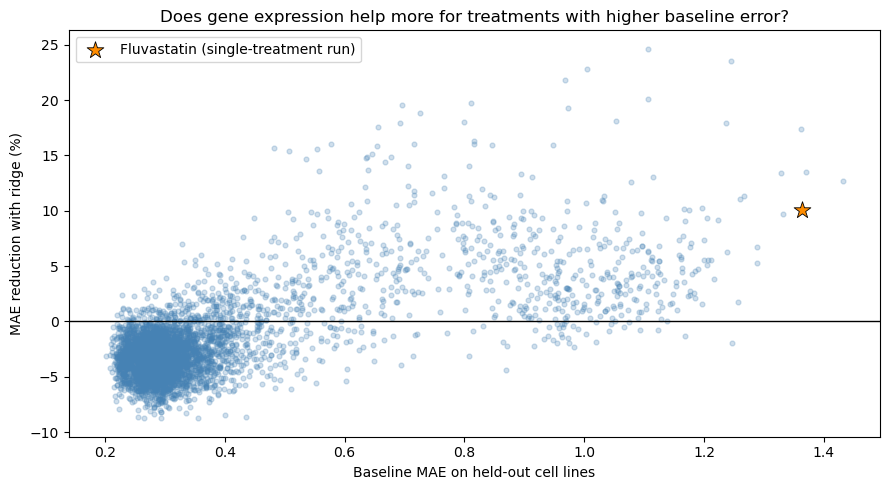

In [91]:
plot_data = screen_results.dropna(subset=["baseline_mae", "ridge_mae"]).copy()
plot_data = plot_data.loc[plot_data["baseline_mae"] > 0]  # Needed for a percentage.
plot_data["mae_reduction_pct"] = (
    100 * (plot_data["baseline_mae"] - plot_data["ridge_mae"])
    / plot_data["baseline_mae"]
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    plot_data["baseline_mae"], plot_data["mae_reduction_pct"],
    s=12, alpha=0.25, color="steelblue",
)
ax.axhline(0, color="black", linewidth=1)

# Mark the earlier fluvastatin result using its reported, rounded MAEs.
fluv_baseline, fluv_ridge = 1.363, 1.226
ax.scatter(
    fluv_baseline, 100 * (fluv_baseline - fluv_ridge) / fluv_baseline,
    marker="*", s=160, color="darkorange", edgecolor="black", linewidth=0.6,
    label="Fluvastatin (single-treatment run)", zorder=3,
)

ax.set(
    xlabel="Baseline MAE on held-out cell lines",
    ylabel="MAE reduction with ridge (%)",
    title="Does gene expression help more for treatments with higher baseline error?",
)
ax.legend()
fig.tight_layout()
plt.show()


Ridge beat the treatment median for 73% of treatments in the highest fifth of response variability, with a median MAE reduction of 2.7%. In the lowest three fifths, it won less than 4% of the time. This suggests that gene expression is most useful for treatments whose responses differ widely across cell lines.
